# Semiparametric Estimation of BSM Physics in Global PDF Fits

**Model:**  
$$\mathbf{D}= [D_1,\dots,D_n]^\top \sim \mathcal{N}\bigl(\bm{\mu}(c),\, \Sigma\bigr)$$
$$D_i = D(x_i, Q_i^2), \quad \mu_{i}(c) = v(c;Q^2_i)\,T[f], \quad i=1,\dots,n$$

where
- $v(c;Q^2) = 1 + k_{\rm lin}(Q^2)\,c + k_{\rm quad}(Q^2)\,c^2$ encodes new-physics EFT corrections,
- $T[f]$ is the standard-model theory prediction convolved with the PDF $f$,
- $f$ is expanded in a B-spline basis: $f(x) = \sum_k \beta_k B_k(x)$, subject to $\sum_k w_k\beta_k = 1$.

**Goal:** estimate $c$ while treating $f$ as an infinite-dimensional nuisance function.

**Outline**
1. Load Grid/FK Tables
2. Model Configuration
3. True PDF (from LHAPDF)
4. Theory Predictions & Data Generation
5. Fitting
   - 5a. B-spline Basis
   - 5b. Option A — Separate Fit (β first, then c)
   - 5c. Option B — Joint Fit (β and c simultaneously)
   - 5d. One-step Estimator
6. Results
7. Simulation Study

In [1]:
import numpy as np
from scipy.integrate import fixed_quad, quad
import pandas as pd
from matplotlib import pyplot as plt
import lhapdf

from t3_utils import (
    # Basis
    bspline_basis,
    # Model
    klin, kquad, v_c, v_prime_c,
    # Design matrices & theory
    build_f_design_matrix_FK, build_yf_design_matrix_FK,
    build_K_matrix, build_K_prime_matrix,
    T_sm_FK, true_mean, true_mean_basis,
    # Fitting
    fit_beta_c, mle_beta, mle_c, one_step_c,
    # Plotting
    plot_by_Q2,
    # Experiment runners
    setup_experiment, run_single_experiment,
)

---
## 1. Load Grid/FK Table

The grid/FK table is precomputed by `data_T3.py` and stored as a compressed NumPy archive.  
Key arrays:
- `W` — FK table matrix `(N_data, N_grid)`: encodes the DIS cross-section convolution
- `grid` — x-grid `(N_grid,)` that `W` integrates over
- `Sigma` — experimental covariance matrix `(N_data, N_data)`
- `kinematics` — `(N_data, 2)` array of `(x, Q²)` pairs for each data point

In [2]:
data = np.load("Dataset/data_208.npz")

Q0     = data["Q0"]         # reference scale
grid   = data["grid"]       # x-grid for FK table
W      = data["W"]          # FK table  (N_data, N_grid)
Sigma  = data["Sigma"]      # covariance (N_data, N_data)
xQ2    = data["kinematics"] # (x, Q²) pairs  (N_data, 2)

print(f"N_data = {xQ2.shape[0]},  N_grid = {grid.shape[0]}")
print(f"Q² range: [{xQ2[:,1].min():.1f}, {xQ2[:,1].max():.1f}]")

N_data = 248,  N_grid = 50
Q² range: [8.8, 230.0]


---
## 2. Model Configuration

The EFT expansion uses two momentum-suppressed Wilson coefficients:
$$k_{\rm lin}(Q^2) = \frac{Q^2}{\Lambda^2}, \qquad k_{\rm quad}(Q^2) = \frac{Q^4}{\Lambda^4}$$

giving the polynomial factor $v(c;Q^2) = 1 + k_{\rm lin}\,c + k_{\rm quad}\,c^2$.

These are already implemented in `t3_utils` with `Lambda=100` as the default.

In [3]:
Lambda  = 100
Q2_min  = xQ2[:, 1].min()
Q2_max  = xQ2[:, 1].max()

# Wrap klin/kquad so Lambda is fixed for this experiment
_klin  = lambda z: klin(z,  Lambda=Lambda)
_kquad = lambda z: kquad(z, Lambda=Lambda)
_v_c       = lambda c, xQ2: v_c(c, xQ2, klin=_klin, kquad=_kquad)
_v_prime_c = lambda c, xQ2: v_prime_c(c, xQ2, klin=_klin, kquad=_kquad)

# Sanity check: v(c=0) should be 1 everywhere
assert np.allclose(_v_c(0, xQ2), 1.0)

---
## 3. True PDF (from LHAPDF)

We use $T_3$ PDF from the NNPDF4.0 set as the ground-truth PDF:
$$T_3(y) = (u(y)-\bar{u}(y)) - (d(y)-\bar{d}(y)).$$

In [4]:
pdfset = "NNPDF40_nnlo_as_01180"
pdf    = lhapdf.mkPDF(pdfset, 0)

x_min = pdf.xMin
x_max = pdf.xMax
Q2_0  = Q0 ** 2

def _uv_scalar(x, Q2):
    return pdf.xfxQ2(2, x, Q2) / x - pdf.xfxQ2(-2, x, Q2) / x

def _dv_scalar(x, Q2):
    return pdf.xfxQ2(1, x, Q2) / x - pdf.xfxQ2(-1, x, Q2) / x

uv = np.vectorize(_uv_scalar, excluded={"Q2"})
dv = np.vectorize(_dv_scalar, excluded={"Q2"})

def f(x):
    return uv(x, Q2_0) - dv(x, Q2_0)

print(f"x range: [{x_min}, {x_max}]")
print("Integral of f over x range:", fixed_quad(f, x_min, x_max, n=1000)[0])

LHAPDF 6.5.4 loading /home/richard/miniconda3/envs/hep/share/LHAPDF/NNPDF40_nnlo_as_01180/NNPDF40_nnlo_as_01180_0000.dat
NNPDF40_nnlo_as_01180 PDF set, member #0, version 1; LHAPDF ID = 331100
x range: [1e-09, 1.0]
Integral of f over x range: 0.9999979255924334


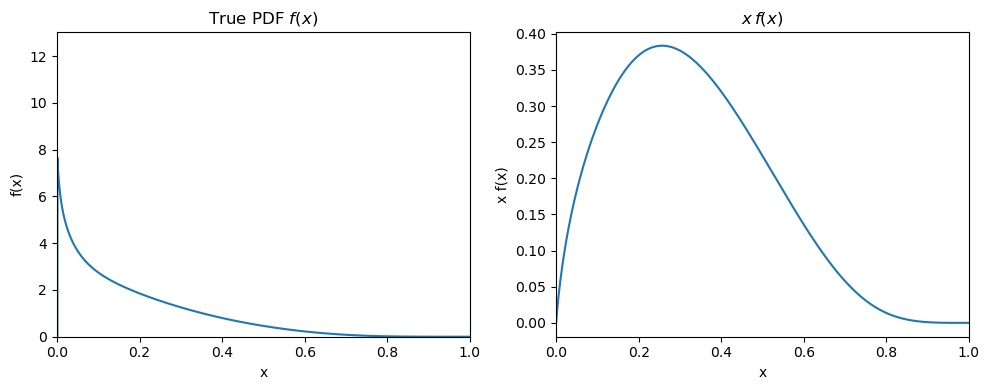

In [5]:
pt = np.linspace(x_min, x_max, 1000)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(pt, f(pt))
ax1.set_xlim(0, 1); ax1.set_ylim(0, None)
ax1.set_xlabel("x"); ax1.set_ylabel("f(x)"); ax1.set_title("True PDF $f(x)$")

ax2.plot(pt, pt * f(pt))
ax2.set_xlim(0, 1)
ax2.set_xlabel("x"); ax2.set_ylabel("x f(x)"); ax2.set_title("$x\,f(x)$")

plt.tight_layout(); plt.show()

---
## 4. Theory Predictions & Data Generation

The SM prediction is $T[f] = W \cdot f(\text{grid})$.  
The full mean at true $c$ is $\mu = v(c;\mathbf{Q}^2) \odot T[f]$.

In [6]:
# Standard-model theory prediction
T = T_sm_FK(f=f, W=W, grid=grid)

# True Wilson coefficient and full mean
c_true = 10
mu     = true_mean(c=c_true, T=T, xQ2=xQ2, klin=_klin, kquad=_kquad)

# Simulate one dataset
rng = np.random.default_rng(seed=42)
D   = rng.multivariate_normal(mean=mu, cov=Sigma)

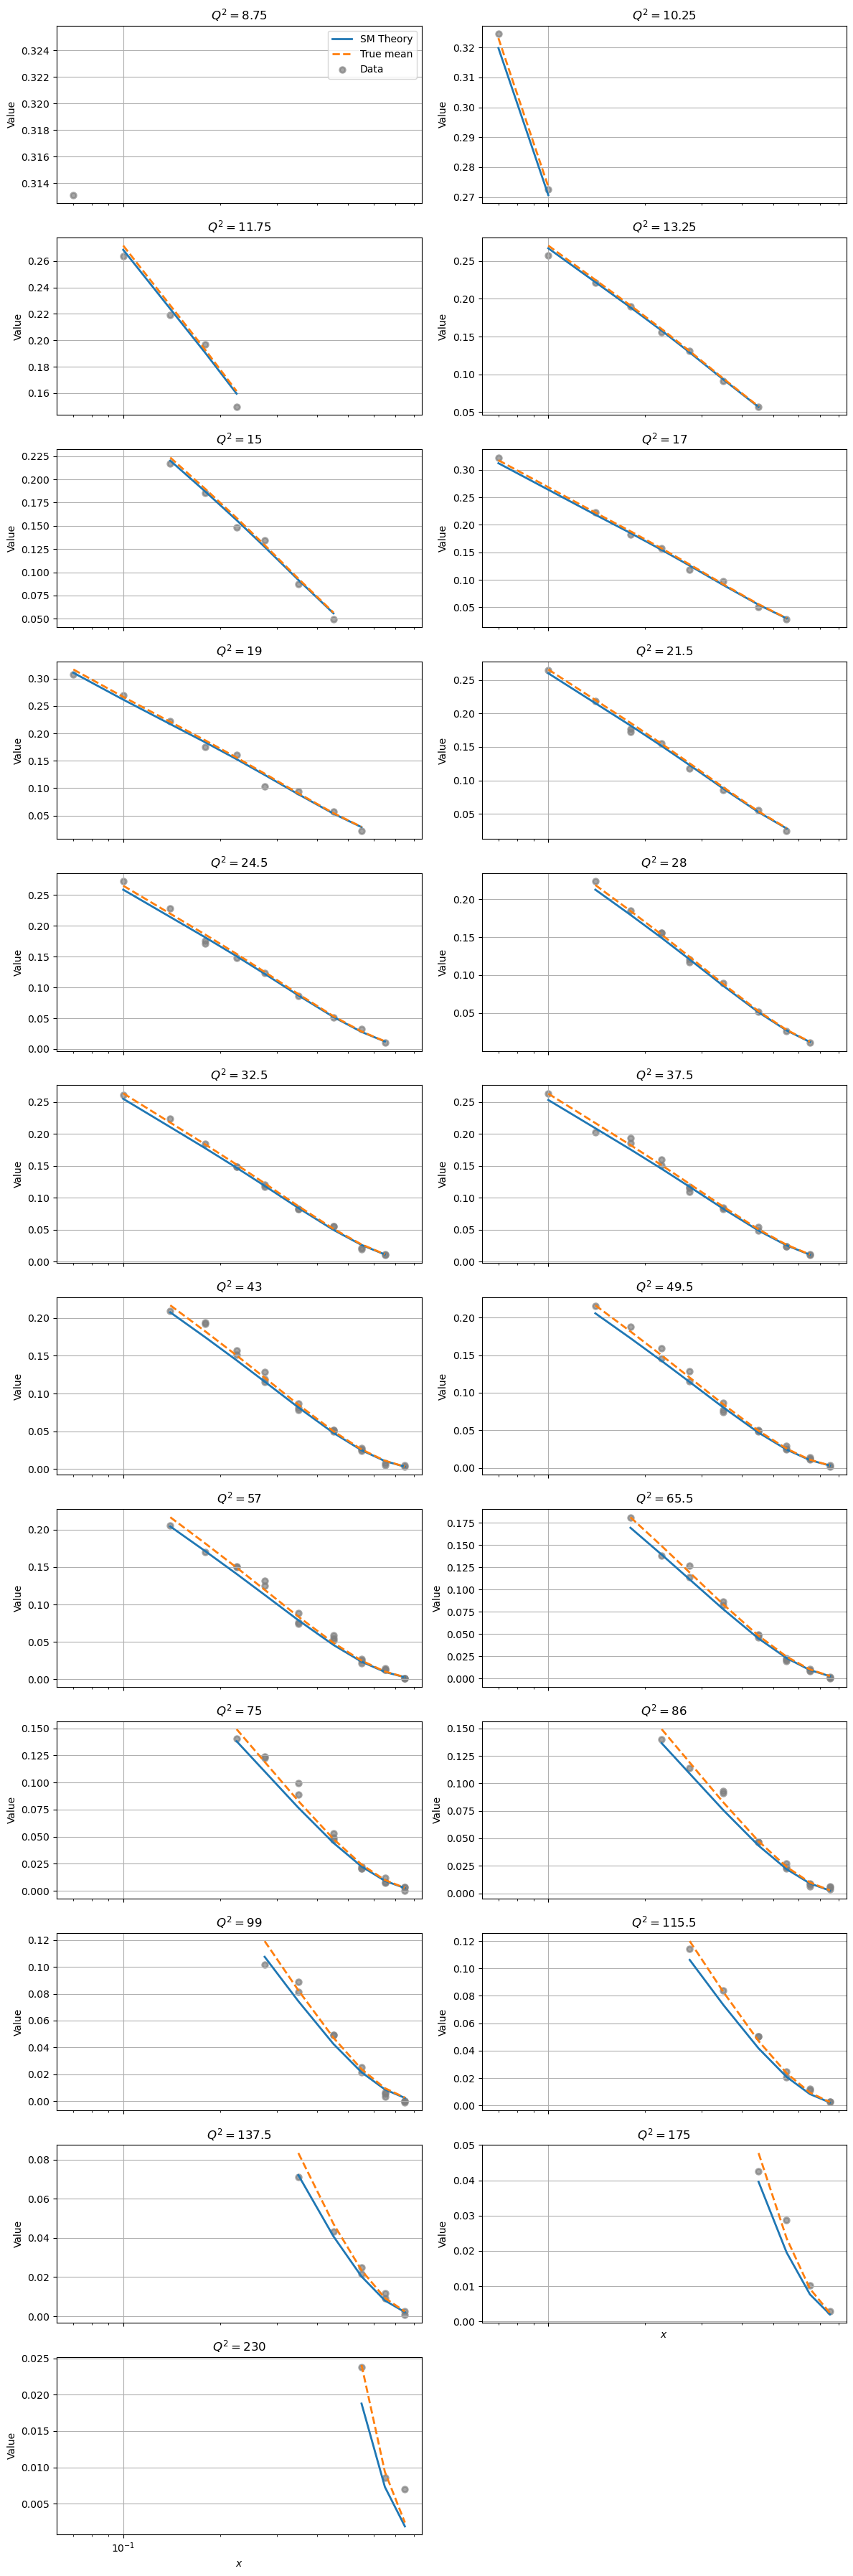

In [7]:
plot_by_Q2(
    {"SM Theory": T, "True mean": mu, "Data": D},
    xQ2=xQ2, ncols=2, x_log_scale=True,
    series_styles={
        "SM Theory": dict(linestyle="-",  linewidth=2, color="C0"),
        "True mean": dict(linestyle="--", linewidth=2, color="C1"),
        "Data":      dict(kind="scatter", color="gray", s=30, alpha=0.7),
    }
)

---
## 5. Fitting

### 5a. B-spline Basis

Set `parametrize = "f"` to expand $f(x)$ directly, or `"xf"` to expand $xf(x)$.

**`"f"` mode:** $f(x) \approx \sum_k \beta_k B_k(x)$, normalization $\mathbf{w}^\top\boldsymbol{\beta}=1$ with $w_k = \int B_k(x)\,dx$.

**`"xf"` mode:** $xf(x) \approx \sum_k \beta_k B_k(x)$, so $f(x) = \frac{1}{x}\sum_k \beta_k B_k(x)$, normalization $w_k = \int B_k(x)/x\,dx$.

The design matrix $A \in \mathbb{R}^{N \times M}$ satisfies $T[f] \approx A\boldsymbol{\beta}$ in both cases.

In [8]:
degree      = 3    # cubic B-splines
M           = 10   # number of basis functions
parametrize = "xf"  # "f": expand f(x);  "xf": expand x*f(x)

B = bspline_basis(degree, M, x_min, x_max)

if parametrize == "f":
    w_norm = np.array([Bk.integrate(x_min, x_max) for Bk in B])
    A      = build_f_design_matrix_FK(B=B, W=W, grid=grid)
elif parametrize == "xf":
    w_norm = np.array([quad(lambda y, Bk=Bk: Bk(y) / y, x_min, x_max)[0] for Bk in B])
    A      = build_yf_design_matrix_FK(B=B, W=W, grid=grid)
else:
    raise ValueError(f"parametrize must be 'f' or 'xf', got {parametrize!r}")

print(f"Parametrize : {parametrize}")
print(f"Design matrix shape: {A.shape}  (N_data × M)")
print(f"w_norm: {w_norm.round(4)}")

Parametrize : xf
Design matrix shape: (248, 10)  (N_data × M)
w_norm: [16.944   1.3863  0.7849  0.5573  0.3471  0.2555  0.2028  0.1302  0.0783
  0.0368]


### 5b. Option A — Separate Fit

**Step 1:** Fix $c = c_0$ (e.g. $c_0 = 0$) and find $\hat{\boldsymbol{\beta}}$ by minimizing the NLL over $\boldsymbol{\beta}$:
$$\hat{\boldsymbol{\beta}} = \arg\min_{\mathbf{w}^\top\boldsymbol{\beta}=1,\;\boldsymbol{\beta}\ge 0} \ell(\boldsymbol{\beta},\, c_0)$$

**Step 2:** Plug $\hat{\boldsymbol{\beta}}$ in and find $\hat{c}$ by minimizing the NLL over $c$:
$$\hat{c} = \arg\min_c\; \ell(\hat{\boldsymbol{\beta}},\, c)$$

This choice is physically well motivated: PDFs are extracted from global fits assuming the Standard Model (i.e., $c=0$), after which the fitted PDFs are used to determine the best-fit value of $c$.

In [9]:
# Step 1: fit beta with c fixed at c0=0
c0 = 0
beta_hat_sep, beta_history = mle_beta(
    D=D, A=A, c=c0, v=_v_c, xQ2=xQ2,
    Sigma=Sigma, w_norm=w_norm,
    nonneg_beta=True, fix_ends=True,
    beta_opt="SLSQP", return_history=True, loss_scale=1e2,
)

# Step 2: fit c with beta fixed
c_hat_sep = mle_c(
    D=D, A=A, v=_v_c, beta=beta_hat_sep,
    xQ2=xQ2, Sigma=Sigma,
    c_opt="scipy_optimize",
)

print(f"True c            = {c_true}")
print(f"Separate fit c    = {c_hat_sep:.4f}")
print(f"Normalization w·β = {w_norm @ beta_hat_sep:.6f}  (should be 1)")

True c            = 10
Separate fit c    = 5.8587
Normalization w·β = 1.000000  (should be 1)


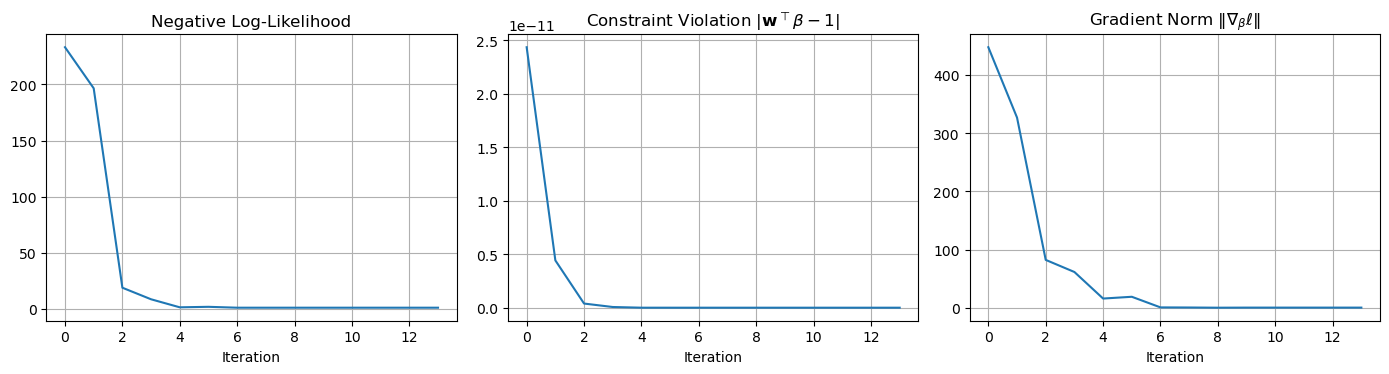

In [10]:
# Convergence diagnostics for the beta fit (separate fit)
beta_hist_df = pd.DataFrame(beta_history)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(beta_hist_df["loss"])
axes[0].set_title("Negative Log-Likelihood")
axes[0].set_xlabel("Iteration"); axes[0].grid()

axes[1].plot(beta_hist_df["constr_viol"])
axes[1].set_title("Constraint Violation $|\\mathbf{w}^\\top\\beta - 1|$")
axes[1].set_xlabel("Iteration"); axes[1].grid()

axes[2].plot(beta_hist_df["grad_norm"])
axes[2].set_title("Gradient Norm $\\|\\nabla_\\beta \\ell\\|$")
axes[2].set_xlabel("Iteration"); axes[2].grid()

plt.tight_layout(); plt.show()

### 5c. Option B — Joint Fit

Jointly minimize the NLL over $(\boldsymbol{\beta}, c)$ simultaneously:
$$\bigl(\hat{\boldsymbol{\beta}},\, \hat{c}\bigr) = \arg\min_{\mathbf{w}^\top\boldsymbol{\beta}=1,\;\boldsymbol{\beta}\ge 0}\; \ell(\boldsymbol{\beta},\, c)$$

In [11]:
res, history = fit_beta_c(
    D=D, A=A, v=_v_c, v_prime=_v_prime_c,
    w_norm=w_norm, xQ2=xQ2, Sigma=Sigma,
    nonneg_beta=True, fix_ends=True,
    return_history=True, opt_method="SLSQP", loss_scale=1e2
)

beta_hat_joint = res.beta_hat
c_hat_joint    = res.c_hat

print(f"True c            = {c_true}")
print(f"Joint fit c       = {c_hat_joint:.4f}")
print(f"Normalization w·β = {w_norm @ beta_hat_joint:.6f}  (should be 1)")

True c            = 10
Joint fit c       = 7.8792
Normalization w·β = 1.000000  (should be 1)


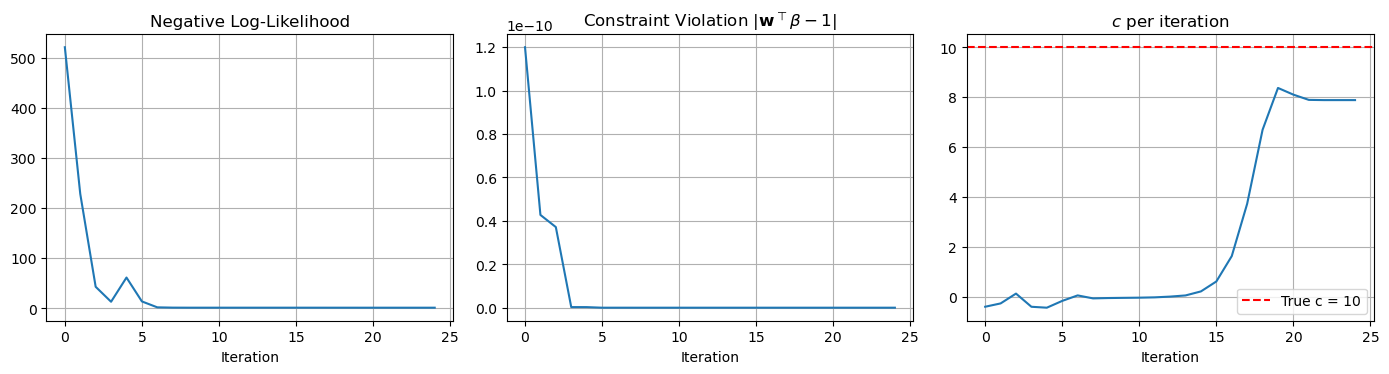

In [12]:
# Convergence diagnostics for the joint fit
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(history_df["loss"])
axes[0].set_title("Negative Log-Likelihood")
axes[0].set_xlabel("Iteration"); axes[0].grid()

axes[1].plot(history_df["constr_viol"])
axes[1].set_title("Constraint Violation $|\mathbf{w}^\\top\\beta - 1|$")
axes[1].set_xlabel("Iteration"); axes[1].grid()

axes[2].plot(history_df["c"])
axes[2].axhline(c_true, color="red", linestyle="--", label=f"True c = {c_true}")
axes[2].set_title("$c$ per iteration")
axes[2].set_xlabel("Iteration"); axes[2].legend(); axes[2].grid()

plt.tight_layout(); plt.show()

In [13]:
# Compare the two fitting strategies
print(f"{'':20s}  {'c_hat':>10s}  {'bias':>10s}")
print(f"{'True c':20s}  {c_true:>10.4f}")
print(f"{'Separate fit':20s}  {c_hat_sep:>10.4f}  {c_hat_sep - c_true:>10.4f}")
print(f"{'Joint fit':20s}  {c_hat_joint:>10.4f}  {c_hat_joint - c_true:>10.4f}")

                           c_hat        bias
True c                   10.0000
Separate fit              5.8587     -4.1413
Joint fit                 7.8792     -2.1208


**Choose which estimate to carry forward.**  
Edit the cell below to select `"separate"` or `"joint"`.

In [14]:
method = "separate"   # <-- change to "separate" to use the separate fit

if method == "joint":
    beta_hat, c_hat = beta_hat_joint, c_hat_joint
else:
    beta_hat, c_hat = beta_hat_sep, c_hat_sep

### 5d. One-step Estimator

The plug-in MLE $\hat c$ is biased due to the first-order bias from estimating the PDF function $f$.

The one-step estimator corrects this using the efficient influence function (EIF):
$$\hat c_{\rm one-step} = \hat c + \frac{\delta^\top \Sigma^{-1}(D - \hat\mu)}{\delta^\top \Sigma^{-1} \delta}$$
where $\delta = \partial_c \hat\mu - K h^*$ is the component of $\partial_c \hat\mu$ orthogonal to the nuisance tangent space $\{Kh : \mathbf{w}^\top h = 0\}$.

In [15]:
K       = build_K_matrix(c_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)
K_prime = build_K_prime_matrix(c_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)

c_one_step, info = one_step_c(D, K, K_prime, beta_hat, c_hat, w_norm, Sigma=Sigma)

print(f"True c          = {c_true}")
print(f"Plug-in ({method:8s}) = {c_hat:.4f}  (bias = {c_hat - c_true:+.4f})")
print(f"One-step        = {c_one_step:.4f}  (bias = {c_one_step - c_true:+.4f})")
print(f"EIF correction  = {info['eif']:.4f}")

True c          = 10
Plug-in (separate) = 5.8587  (bias = -4.1413)
One-step        = 9.0567  (bias = -0.9433)
EIF correction  = 3.1980


---
## 6. Results

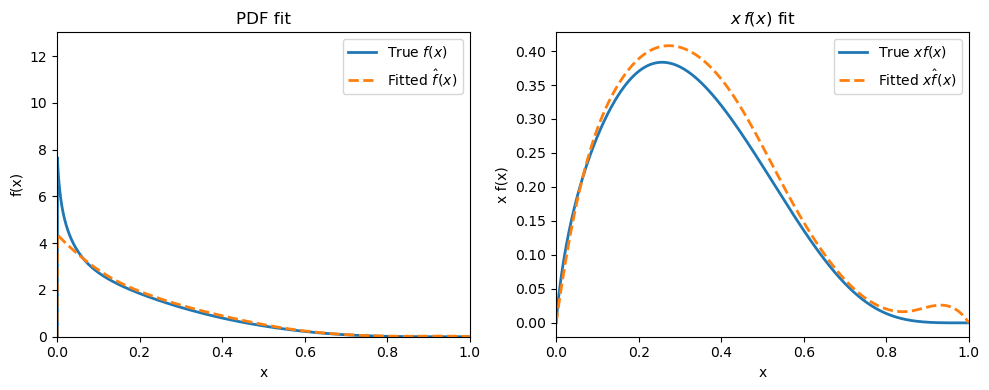

In [16]:
# PDF estimate vs truth
pt        = np.linspace(x_min, x_max, 1000)
basis_hat = sum(b * Bk(pt) for b, Bk in zip(beta_hat, B))
f_hat     = basis_hat if parametrize == "f" else basis_hat / pt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(pt, f(pt),   lw=2, label="True $f(x)$")
ax1.plot(pt, f_hat,   lw=2, ls="--", label=r"Fitted $\hat f(x)$")
ax1.set_xlim(0, 1); ax1.set_ylim(0, None)
ax1.set_xlabel("x"); ax1.set_ylabel("f(x)"); ax1.set_title("PDF fit"); ax1.legend()

ax2.plot(pt, pt * f(pt),   lw=2, label="True $x f(x)$")
ax2.plot(pt, pt * f_hat,   lw=2, ls="--", label=r"Fitted $x\hat f(x)$")
ax2.set_xlim(0, 1)
ax2.set_xlabel("x"); ax2.set_ylabel("x f(x)"); ax2.set_title("$x\,f(x)$ fit"); ax2.legend()

plt.tight_layout(); plt.show()

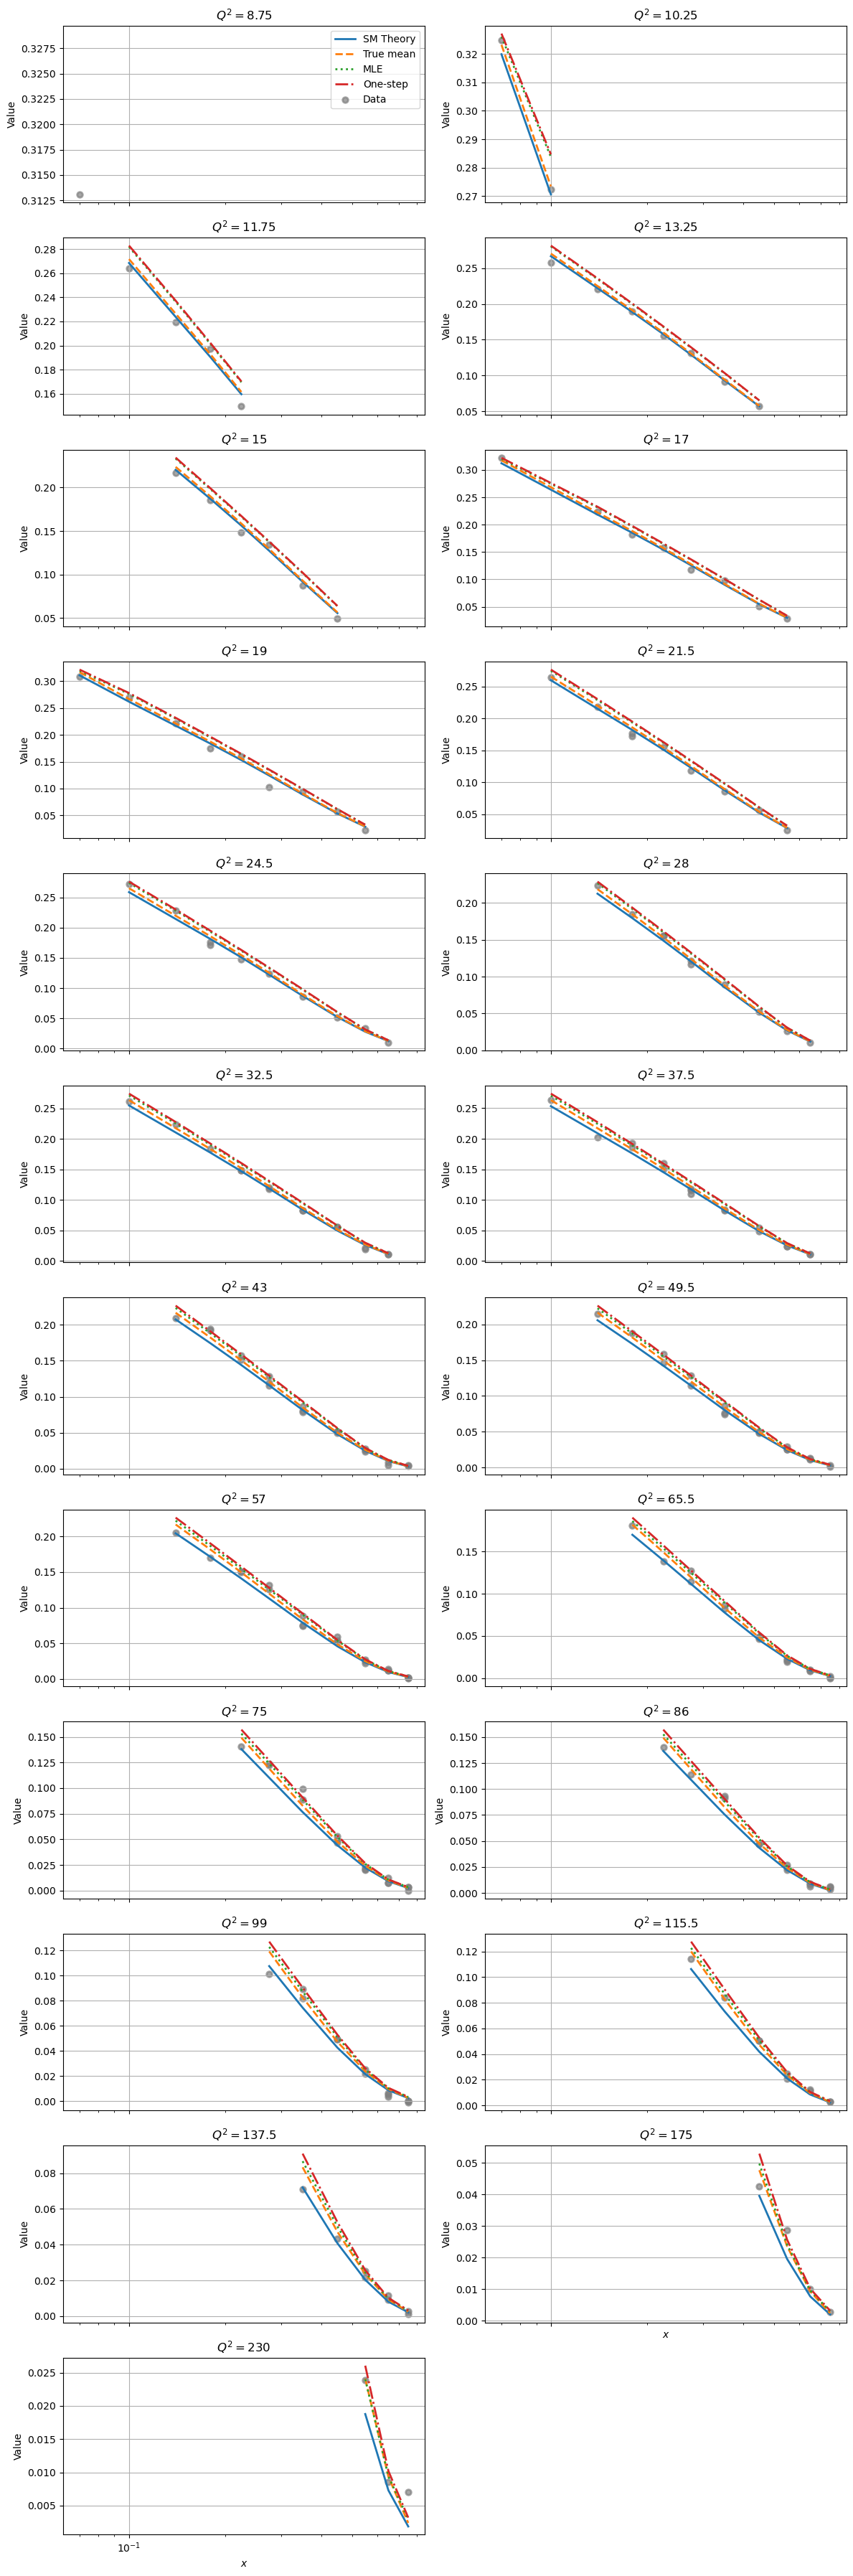

In [17]:
# Mean prediction vs data
mu_hat      = true_mean_basis(c_hat,      beta_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)
mu_one_step = true_mean_basis(c_one_step, beta_hat, A, xQ2=xQ2, klin=_klin, kquad=_kquad)

plot_by_Q2(
    {"SM Theory": T, "True mean": mu, "MLE": mu_hat, "One-step": mu_one_step, "Data": D},
    xQ2=xQ2, ncols=2, x_log_scale=True,
    series_styles={
        "SM Theory": dict(linestyle="-",  linewidth=2, color="C0"),
        "True mean": dict(linestyle="--", linewidth=2, color="C1"),
        "MLE":       dict(linestyle=":",  linewidth=2, color="C2"),
        "One-step":  dict(linestyle="-.", linewidth=2, color="C3"),
        "Data":      dict(kind="scatter", color="gray", s=30, alpha=0.7),
    }
)

---
## 7. Simulation Study

We repeat the experiment $N_{\rm sim}$ times (each with a fresh draw of $\mathbf{D}$) to assess the
sampling distribution of the plug-in MLE and the one-step estimator.

`setup_experiment` pre-computes the basis and design matrix once; `run_single_experiment`
only generates new data and re-runs the optimization.

In [18]:
setup_dict = setup_experiment(
    pdf=pdfset, c=c_true, f=f,
    xQ2=xQ2, grid=grid, W=W,
    degree=degree, M=M,
    data_Sigma=Sigma,
    opt=method,            # uses the "separate" or "joint" choice from Section 5
    parametrize=parametrize,
    c_opt="scipy_optimize", beta_opt="SLSQP",
    c0=0, Lambda=Lambda,
    x_min=x_min, x_max=x_max,
    Q2_min=Q2_min, Q2_max=Q2_max,
    klin=klin, kquad=kquad,
    nonneg_beta=True, fix_ends=True,
    ncol_plots=2, x_log_scale=True,
    return_history=False, loss_scale=1e2,
)

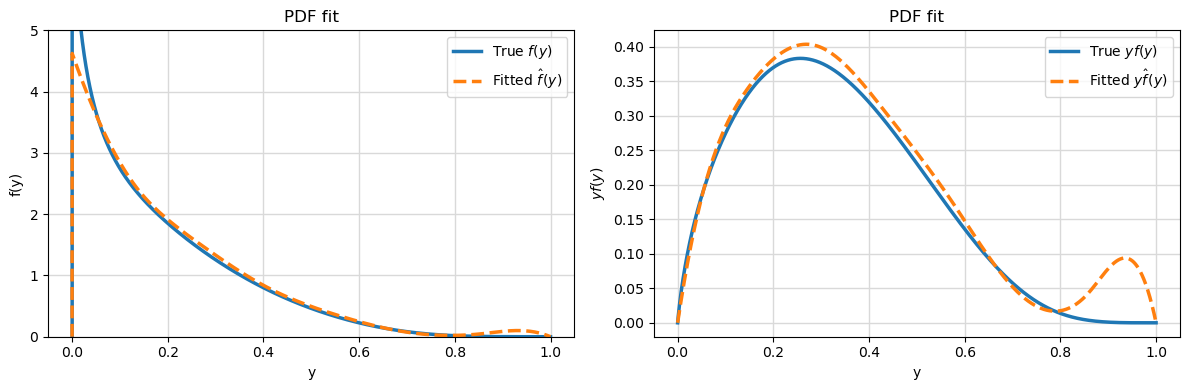

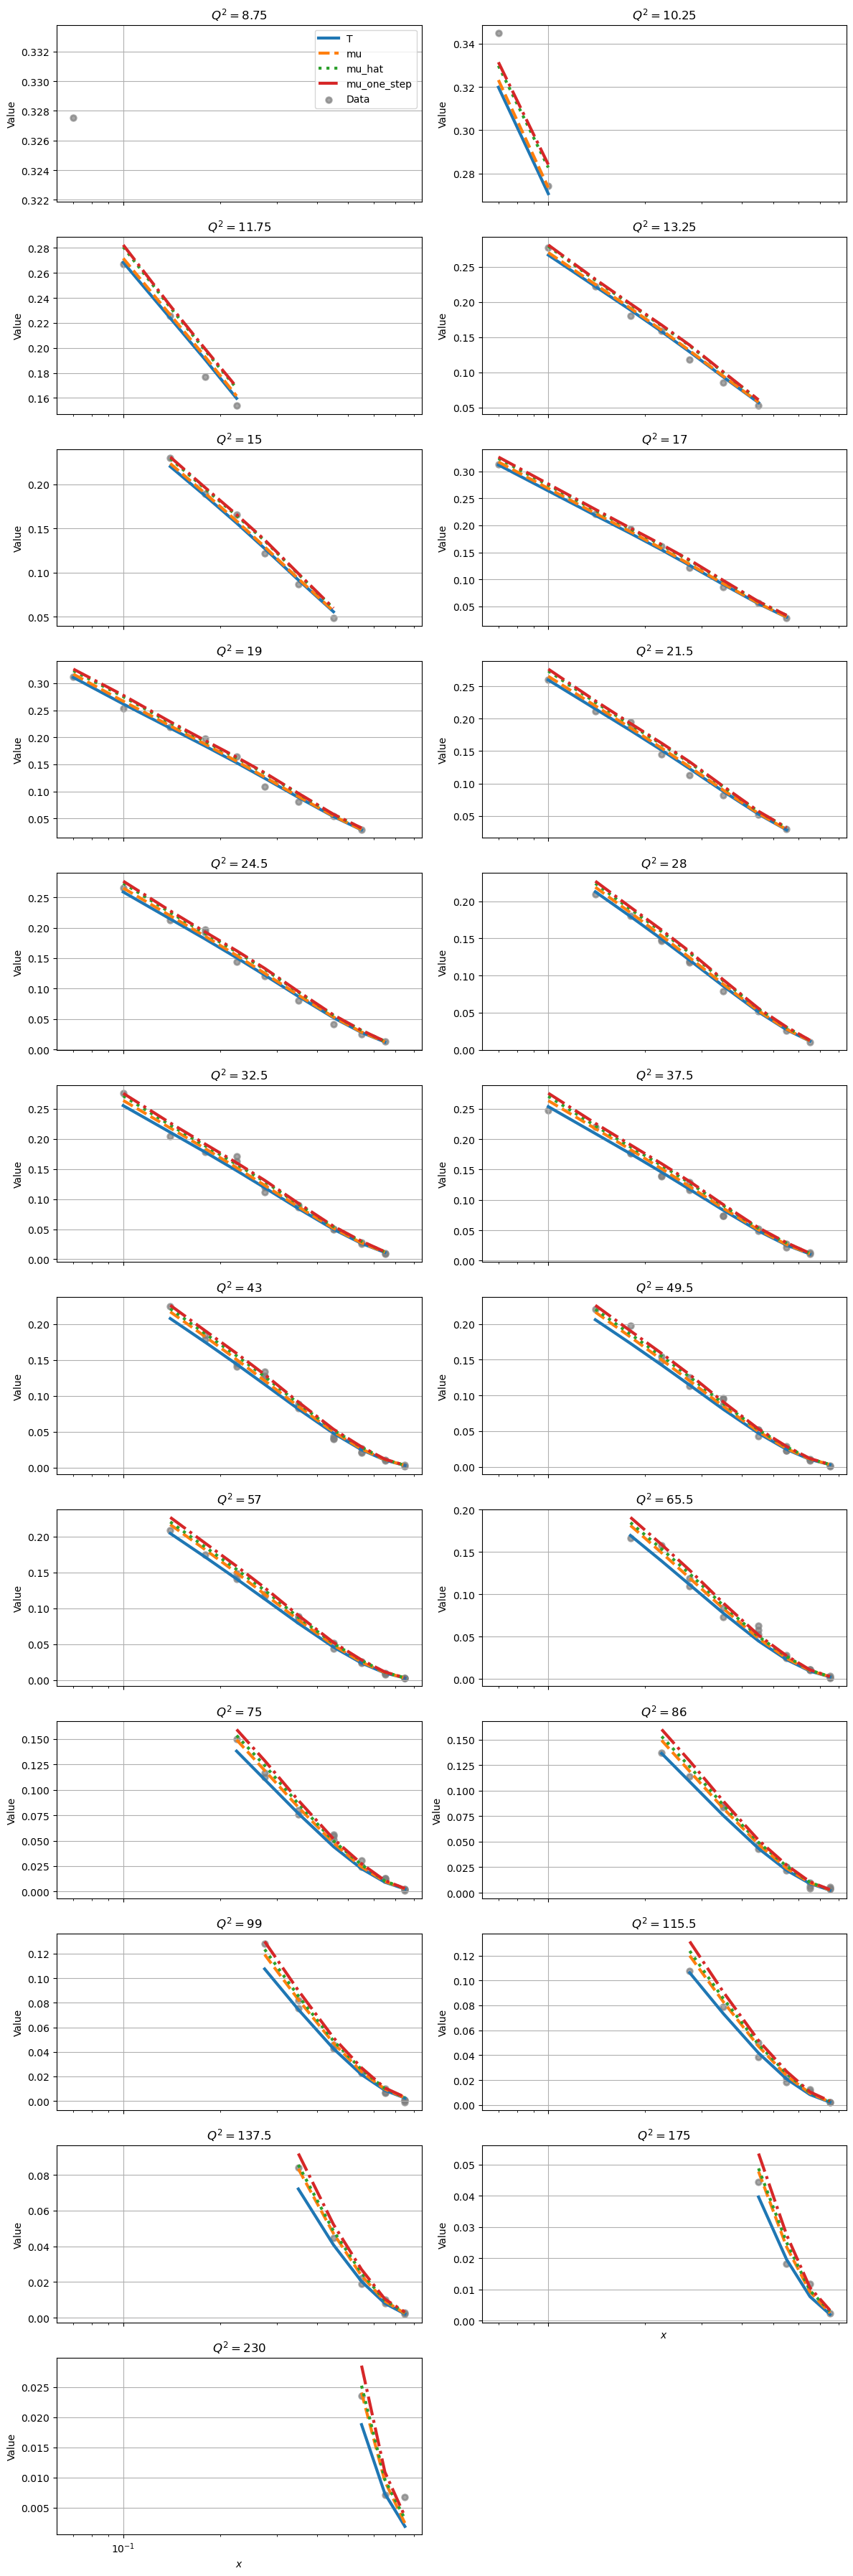

     Parameter      Value
0        c_hat   7.915319
1   c_one_step  12.657119
2       True c  10.000000
3       beta_0   0.000000
4       beta_1   0.220361
5       beta_2   0.357069
6       beta_3   0.437022
7       beta_4   0.310451
8       beta_5   0.184825
9       beta_6   0.017002
10      beta_7   0.000000
11      beta_8   0.156546
12      beta_9   0.000000
Normalization constraint (w^T beta_hat): 1.0
Fitted pdf integrates to (xf parametrize): 1.0000000266807763


In [19]:
# Quick diagnostic on one draw before the full simulation
c_hat_diag, c_one_step_diag, info_diag = run_single_experiment(setup_dict, diagnostics=True)

In [20]:
N_sim = 500
plug_in_estimates  = np.zeros(N_sim)
one_step_estimates = np.zeros(N_sim)

for sim in range(N_sim):
    c_hat_i, c_one_step_i = run_single_experiment(setup_dict, diagnostics=False)
    plug_in_estimates[sim]  = c_hat_i
    one_step_estimates[sim] = c_one_step_i
    if (sim + 1) % 50 == 0:
        print(f"  {sim+1}/{N_sim} done")

print("\n--- Results ---")
for label, est in [("Plug-in", plug_in_estimates), ("One-step", one_step_estimates)]:
    print(f"{label:10s}  mean={est.mean():.4f} median={np.median(est):.4f} bias={est.mean()-c_true:.4f} std={est.std():.4f}")
print(f"True c = {c_true}")

  50/500 done
  100/500 done
  150/500 done
  200/500 done
  250/500 done
  300/500 done
  350/500 done
  400/500 done
  450/500 done
  500/500 done

--- Results ---
Plug-in     mean=5.8581 median=6.0560 bias=-4.1419 std=2.2421
One-step    mean=10.1925 median=10.2895 bias=0.1925 std=3.4731
True c = 10


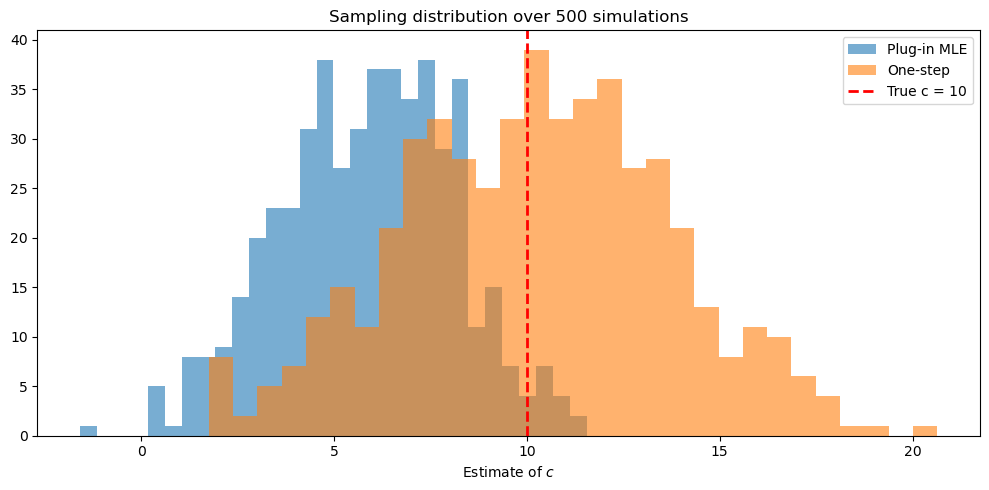

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(plug_in_estimates,  bins=30, alpha=0.6, color="C0", label="Plug-in MLE")
ax.hist(one_step_estimates, bins=30, alpha=0.6, color="C1", label="One-step")
ax.axvline(c_true, color="red", linestyle="--", linewidth=2, label=f"True c = {c_true}")
ax.set_xlabel("Estimate of $c$")
ax.set_title(f"Sampling distribution over {N_sim} simulations")
ax.legend()
plt.tight_layout(); plt.show()